# Time-series analysis with Python

The required assignment develops a harmonic least-squares spectrum and applies it to synthetic signals, Sun/GOLF observations, Procyon statistical weights and observing gaps.

See [Supplementary theory](THEORY.md) for the lecture background on normalization, sampling, spectral windows, weights and mode coherence.

The cells below display the saved analysis. Set `RUN_ANALYSIS = True` to recalculate after following the data-download instructions in the [README](README.md).

In [1]:
from pathlib import Path
import json
from IPython.display import display, Image

ROOT = Path.cwd()
RUN_ANALYSIS = False
if RUN_ANALYSIS:
    from main_analysis import run_analysis
    main = run_analysis(ROOT, show=False)
else:
    main = json.loads((ROOT / "results/main_summary.json").read_text())
print("Recalculated main analysis." if RUN_ANALYSIS else "Displaying saved main results.")
print(f"Maximum coherent-width relative error: {100 * main['max_synthetic_width_relative_error']:.3f}%")
print(f"Procyon high-frequency amplitude reduction: {100 * main['procyon_mean_noise_amplitude_reduction']:.2f}%")

Displaying saved main results.
Maximum coherent-width relative error: 0.126%
Procyon high-frequency amplitude reduction: 41.79%


## 1. Software and method

At each user-selected trial frequency, the program minimizes the weighted squared residuals of a sine/cosine model. With times in seconds relative to the first observation,

$$
m_i=\alpha s_i+\beta c_i,\qquad s_i=\sin(\omega t_i),\quad c_i=\cos(\omega t_i),\quad \omega=2\pi f_{\mu\mathrm{Hz}}10^{-6}.
$$

Define the weighted sums

$$
S=\sum_iw_is_i^2,\quad C=\sum_iw_ic_i^2,\quad Z=\sum_iw_is_ic_i,\quad Y_s=\sum_iw_iy_is_i,\quad Y_c=\sum_iw_iy_ic_i.
$$

The finite-sampling correction retains the cross term between the two quadratures:

$$
\alpha=\frac{Y_sC-Y_cZ}{SC-Z^2},\qquad \beta=\frac{Y_cS-Y_sZ}{SC-Z^2},\qquad A=\sqrt{\alpha^2+\beta^2},\quad P=A^2.
$$

Frequency input and output use microhertz. The output power is fitted amplitude squared, not power spectral density. Real observations have their ordinary or weighted mean removed before fitting; the intercept is not fitted simultaneously. Known zero-baseline synthetic signals omit this centering. Common rescaling of the weights leaves the fit unchanged, and singular fits return NaN with a warning.

**Running the software.** Follow the [README](README.md) installation and data-download commands, then run `python main_analysis.py`. It writes spectra, summary tables and figures. For another dataset, `python time_series.py --help` describes the CSV interface. Set `--frequency-min`, `--frequency-max` and `--frequency-step`; select `--time-unit d` for days. Procyon's SNR weights use `--weight-column 2` (zero-based indexing). The Python files contain the numerical source code.

## 2. Simple harmonic signals

Changing one property at a time verifies the estimator. Oscillations at 800, 1600 and 2400 μHz recover those frequencies on the chosen grid. Injected amplitudes of 0.5, 1 and 2 give peak powers of 0.25, 1 and 4.

For uniformly sampled records lasting one, two and four days, the measured coherent power-peak widths follow

$$
\mathrm{FWHM}_P\simeq\frac{0.8859}{T},\qquad T=N\Delta t.
$$

The maximum relative width discrepancy is 0.126%. Increasing duration narrows the peak; refining the frequency grid only samples that peak more densely.

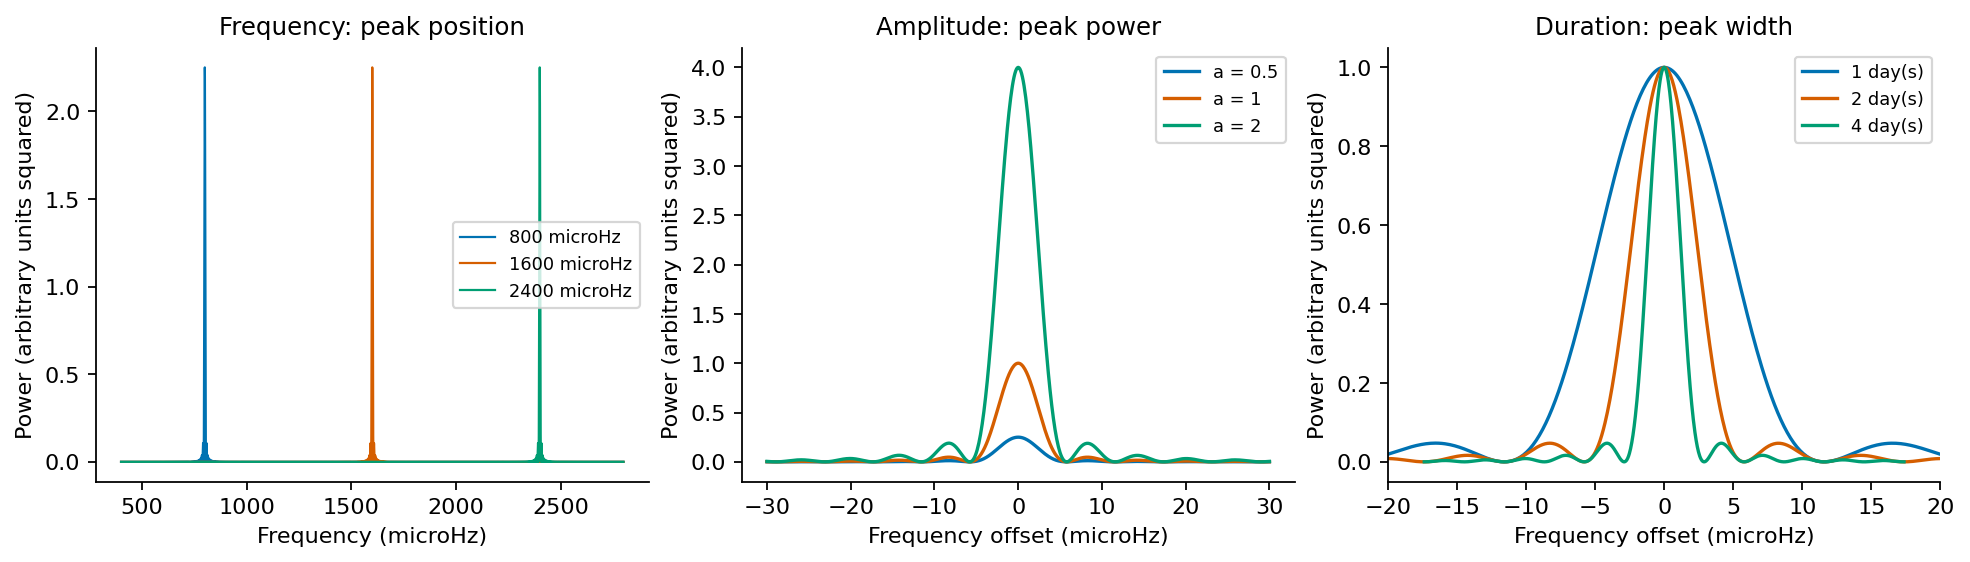

In [2]:
display(Image(filename=str(ROOT / 'figures/01_harmonic_verification.png')))

Figure 1. Spectral changes caused by varying the injected frequency, amplitude and record duration independently.

## 3. Solar oscillations

The GOLF series contains 32,400 velocity measurements over 29.999 days, giving an inverse-span scale of 0.386 μHz. The analysis keeps the supplied timestamps. The broad spectrum locates the oscillation envelope; three local profiles are compared with coherent reference signals at identical observation times.

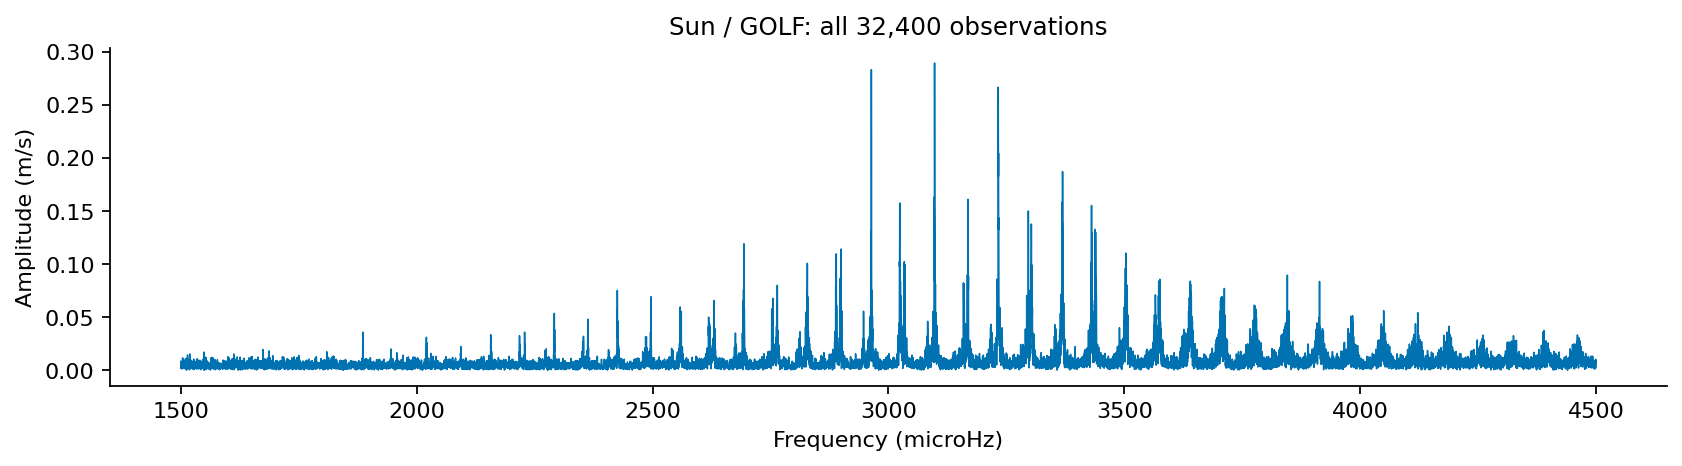

In [3]:
display(Image(filename=str(ROOT / 'figures/02_sun_overview.png')))

Figure 2. Solar amplitude spectrum from the original GOLF observations.

The reference centres are 2963.80, 3097.86 and 3232.82 μHz. Each observed or reference profile is normalized to its own maximum; the selected centres need not coincide exactly with the finest-grid maxima.

The fraction of sampled power outside ±0.6 μHz, relative to the total within ±3 μHz, is 29.5–37.9% for the solar profiles and 5.1% for the coherent reference. A single stable sinusoid through the observing window therefore does not reproduce these profiles. Finite coherence is consistent with this structure, although noise, neighbouring components and splitting can also contribute. This shape comparison does not measure a mode lifetime or an integrated physical variance.

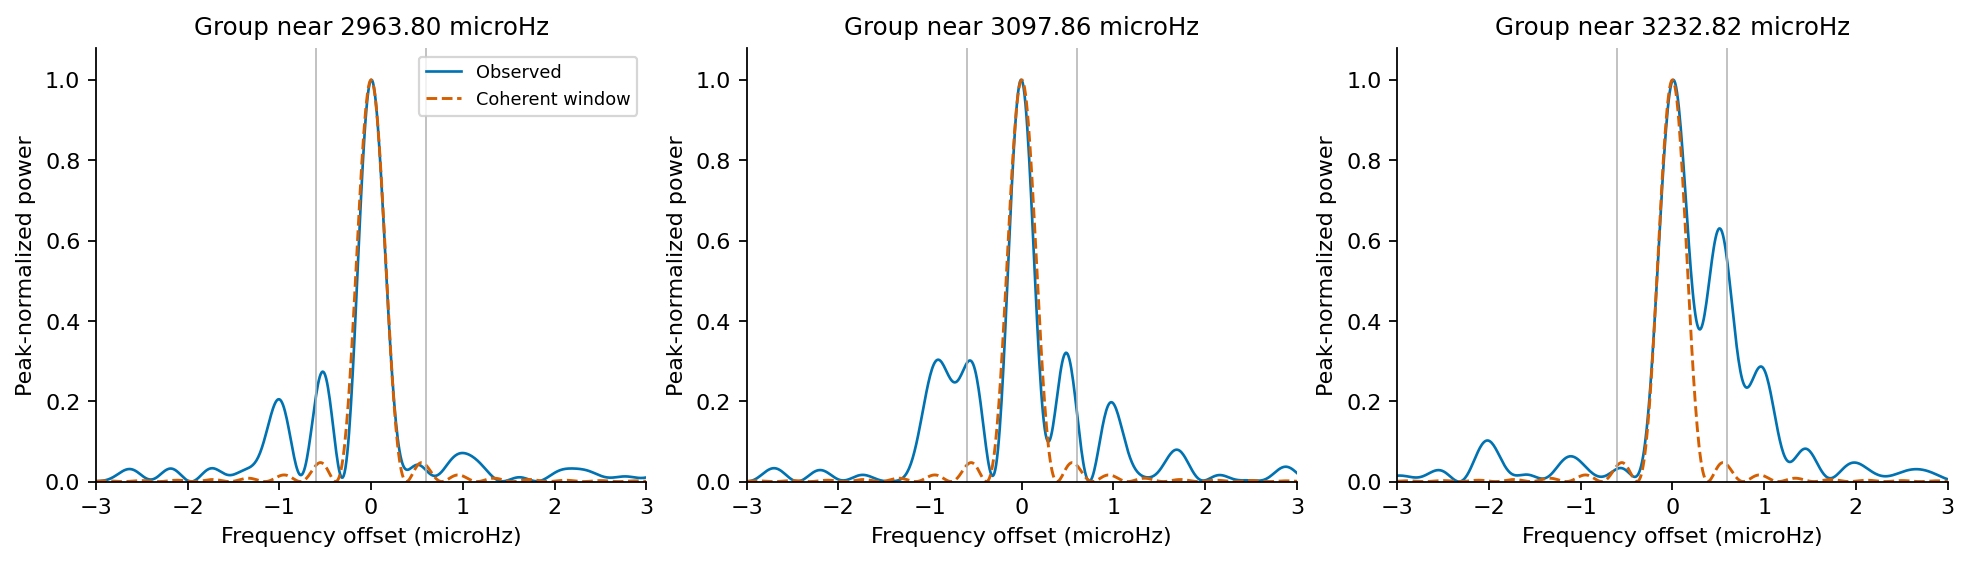

In [4]:
display(Image(filename=str(ROOT / 'figures/03_sun_peak_shapes.png')))

Figure 3. Local solar profiles and coherent references, evaluated with the same timestamps and frequency grid.

## 4. Procyon with and without weights

All 22,529 measurements over 25.024 days are retained, including repeated timestamps. The third column already provides SNR-optimized weights and is used directly. Equal and weighted spectra share their frequency grid and normalization.

In the fixed 2200–3000 μHz comparison band, mean spectral amplitude falls from 0.04338 to 0.02525 m/s, a 41.8% reduction. This is a high-frequency background comparison, not a time-domain RMS measurement or a uniform improvement for every stellar peak.

Weighting also alters the observing window. Its FWHM increases from 0.662 to 1.019 μHz, while relative power at the fixed +1/day offset (11.574 μHz) increases from 0.105 to 0.365. Concentrating weight in particular intervals lowers the measured background but broadens the response and strengthens daily alias ambiguity.

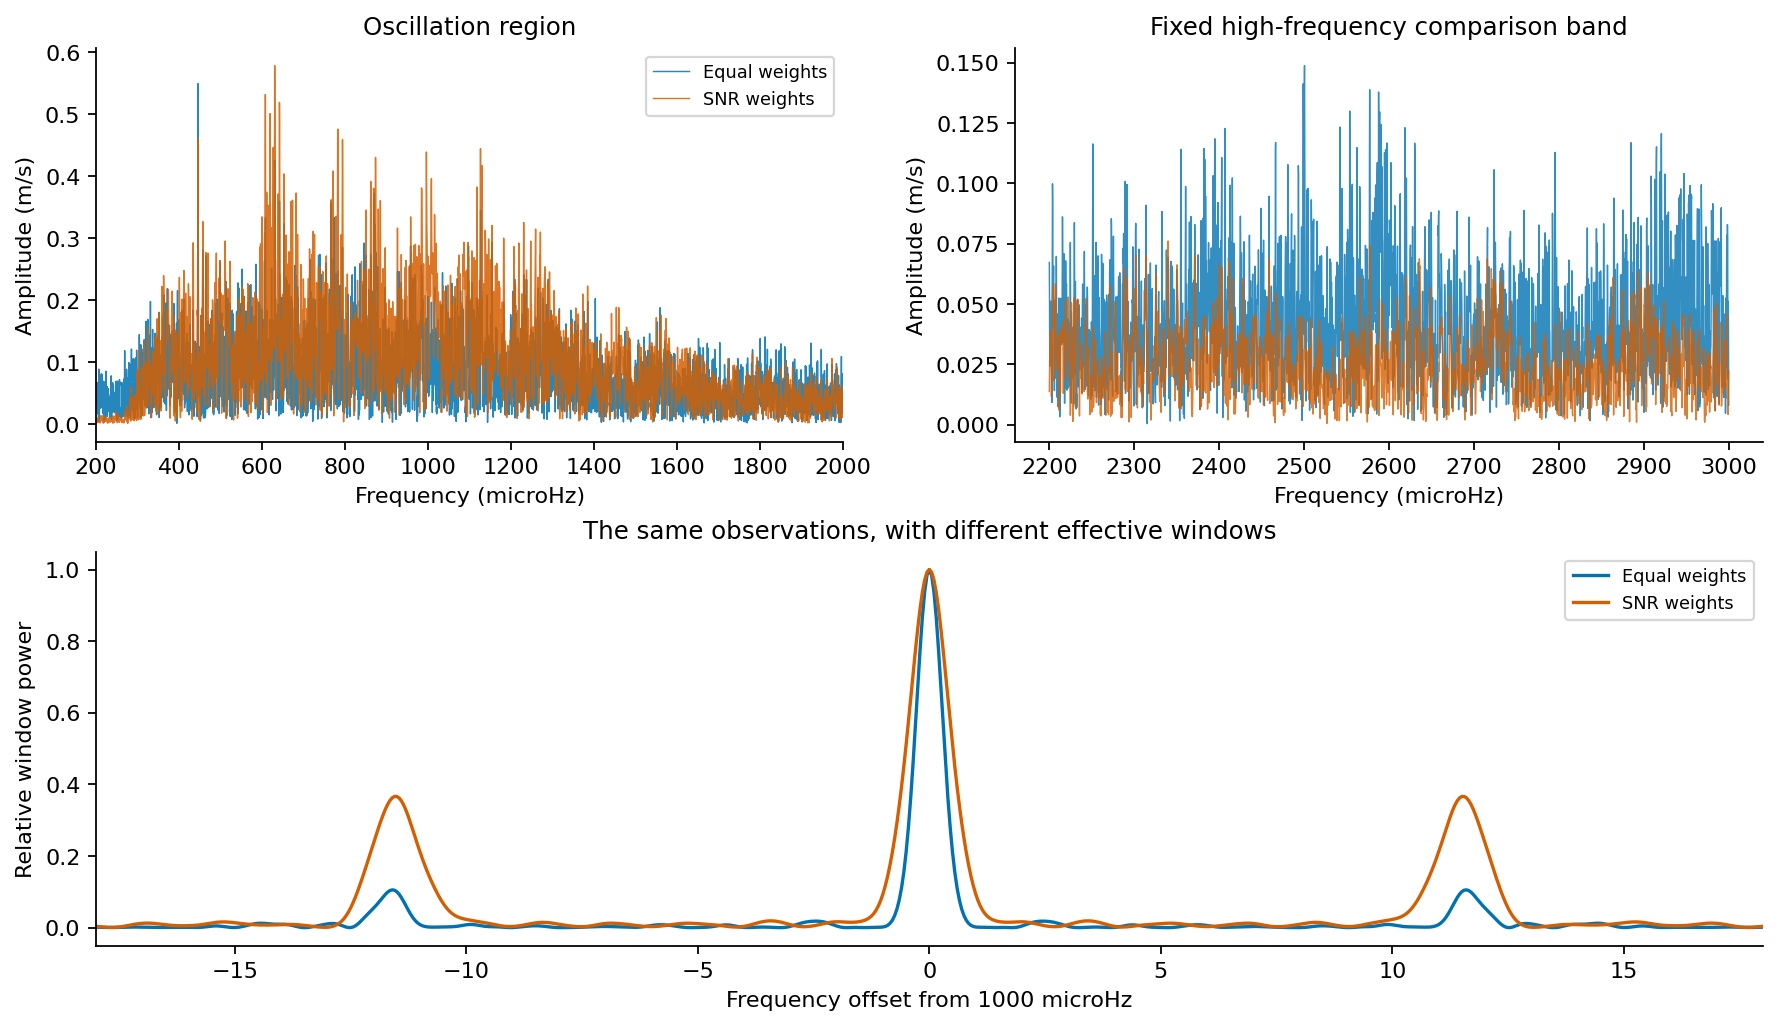

In [5]:
display(Image(filename=str(ROOT / 'figures/04_procyon_weights.png')))

Figure 4. Procyon spectra and phase-averaged windows at 1000 μHz, using equal and SNR weights.

## 5. Spectral windows and observing gaps

The assignment window averages the fitted powers of unit sine and cosine reference signals:

$$
W(f)=\frac{P_{\sin}(f)+P_{\cos}(f)}{2}.
$$

Known-zero baselines are preserved, so the response equals one at the reference frequency. One-day segments sampled every 120 seconds are considered singly and in pairs. Every pair contains 1,440 observations; the gap ranges from zero to four days.

For segment length D and end-to-start gap G, the continuous rectangular-window approximation is

$$
W(f_0+\delta f)\simeq\operatorname{sinc}^2(\pi D\delta f)\cos^2[\pi(D+G)\delta f],\qquad \operatorname{sinc}(x)=\frac{\sin x}{x}.
$$

Here times are in seconds and frequency offsets in Hz. The first positive minimum is 1/D for one segment and 1/[2(D+G)] for a pair. An independent numerical search with parabolic refinement agrees with these predictions within one grid step.

| Gap (days) | Pair's first minimum (μHz) | Largest relative sidelobe |
|---|---:|---:|
| 0 | 5.787 | 0.047 |
| 1 | 2.894 | 0.442 |
| 4 | 1.157 | 0.877 |

Sidelobes are measured within ±35 μHz, outside the central first minima. Zero gap recovers a continuous two-day record. Larger gaps extend the phase baseline and narrow the central response, but permit alternative cycle counts across the gap and produce strong competing peaks. A narrower peak therefore need not give an unambiguous frequency.

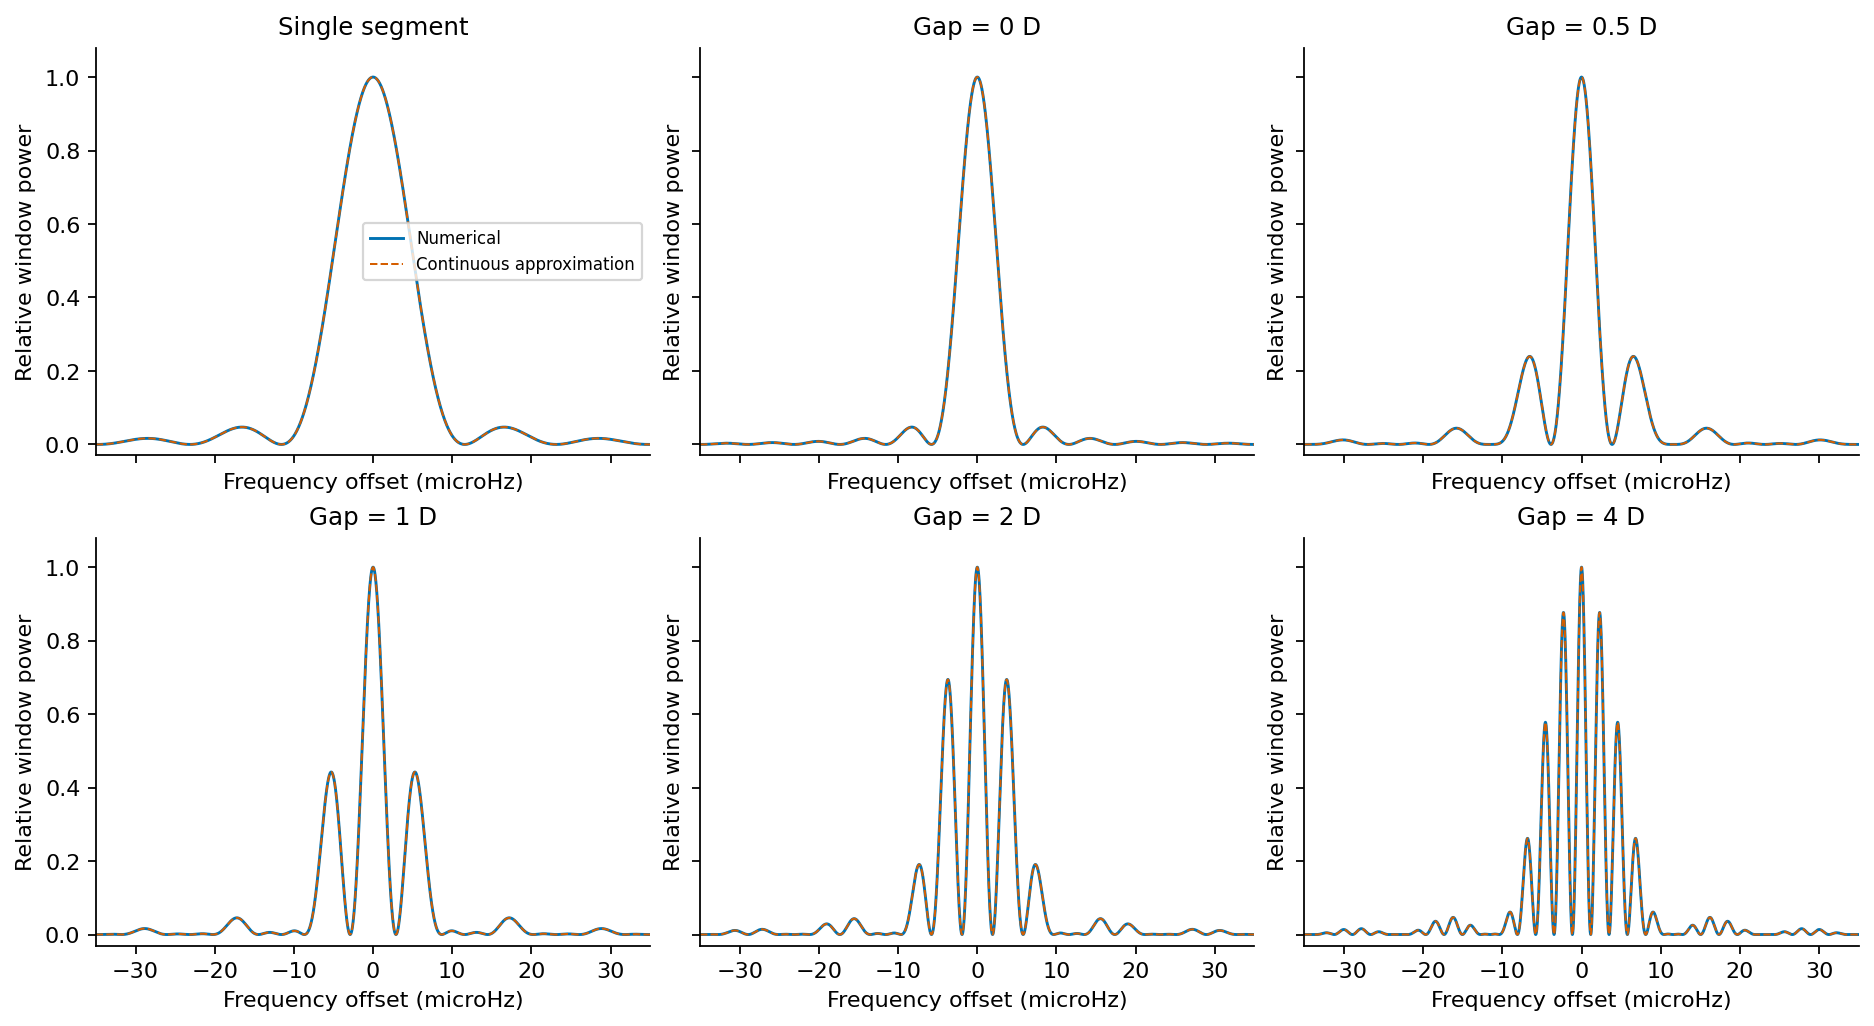

In [6]:
display(Image(filename=str(ROOT / 'figures/05_gap_windows.png')))

Figure 5. Numerical windows and the continuous approximation for single and paired observing segments.

## References

D. Stello, *PHYS4143 Time Series Lecture 1* (2026), PDF pages 61–65: fitting prescription and assignment. The harmonic fit follows Frandsen et al. (1995), A&A 301, 123, section 4.2, as reproduced in the lecture.

Observations: [course data directory](https://www.physics.usyd.edu.au/~stello/timeseries/).